In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

data = {
    'Date': [
        '2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04', '2023-01-05','2023-01-06', '2023-01-07', '2023-01-08', '2023-01-09', '2023-01-10',
        '2023-01-11', '2023-01-12', '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16'
    ],
    'Product': [
        'Product A', 'Product B', 'Product A', 'Product C', 'Product B','Product A', 'Product C', 'Product A', 'Product B', 'Product C',
        'Product A', 'Product B', 'Product C', 'Product A', 'Product B', 'Product C'
    ],
    'Sales': [
        200, 150, 220, 300, 180, 210, 310, 230, 160, 320, 240, 170, 330, 250, 190, 340
    ],
    'Quantity': [
        4, 3, 5, 6, 4, 5, 7, 6, 3, 7, 6, 3, 8, 7, 4, 8
    ],
    'Region': [
        'North', 'South', 'North', 'East', 'West','North', 'East', 'North', 'South', 'East','North', 'South', 'East', 'North', 'South', 'East'
    ]
}
df = pd.DataFrame(data)
print(df.head())

         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         4  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         5  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West


In [ ]:
print(df.isnull().sum())

Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64


In [ ]:
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df = df.dropna(subset=['Product', 'Quantity', 'Region'])

print(df.describe())

            Sales   Quantity
count   16.000000  16.000000
mean   237.500000   5.375000
std     64.031242   1.746425
min    150.000000   3.000000
25%    187.500000   4.000000
50%    225.000000   5.500000
75%    302.500000   7.000000
max    340.000000   8.000000


In [ ]:
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

     Product  Sales  Quantity
0  Product A   1350        33
1  Product B    850        17
2  Product C   1600        36


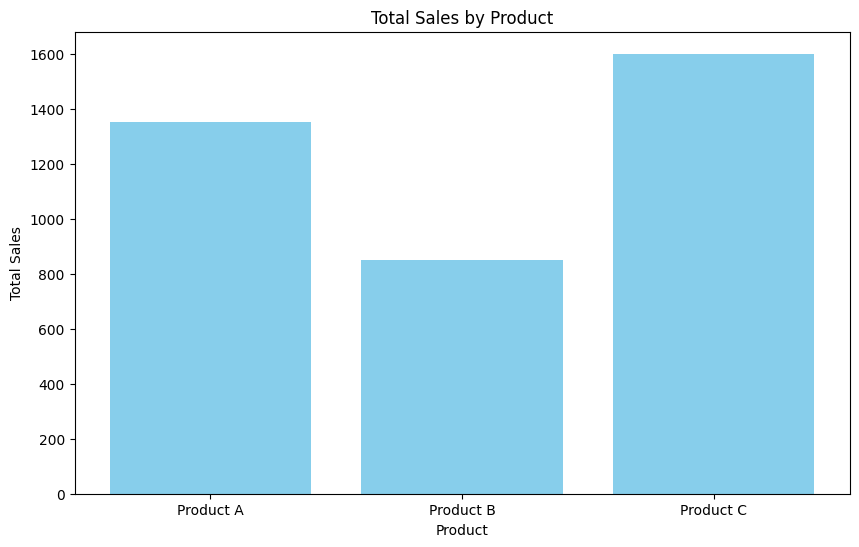

In [ ]:
print(product_summary)

plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'], color='skyblue')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

In [ ]:
pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc='sum', fill_value=0)
print(pivot_table)

Product  Product A  Product B  Product C
Region                                  
East             0          0       1600
North         1350          0          0
South            0        670          0
West             0        180          0


             Sales  Quantity
Sales     1.000000  0.944922
Quantity  0.944922  1.000000


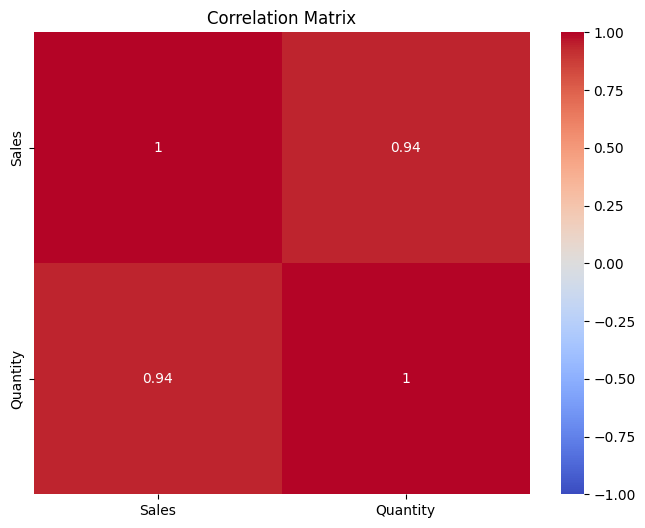

In [ ]:
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()